<a href="https://colab.research.google.com/github/fuger-tw/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [19]:
np.random.seed(10)
tf.random.set_seed(10)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

(x_train_image, y_train_label), (x_test_image, y_test_label) = fashion_mnist.load_data()
print('訓練圖片形狀：', x_train_image.shape)
print('訓練標籤形狀：', y_train_label.shape)
print('測試圖片形狀：', x_test_image.shape)
print('測試標籤形狀：', y_test_label.shape)
print('圖片總數：', len(x_train_image) + len(x_test_image))
print('10 種服飾標籤：', class_names)

訓練圖片形狀： (60000, 28, 28)
訓練標籤形狀： (60000,)
測試圖片形狀： (10000, 28, 28)
測試標籤形狀： (10000,)
圖片總數： 70000
10 種服飾標籤： ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


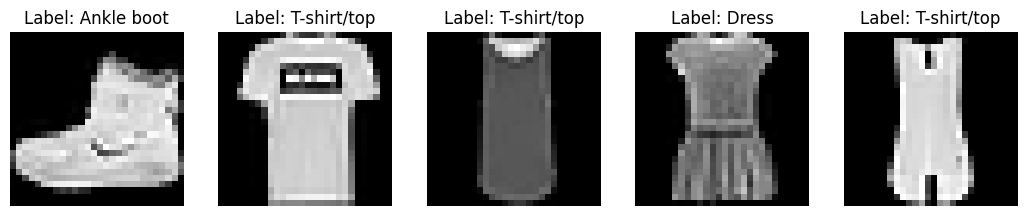

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for i, ax in enumerate(axes):
    ax.imshow(x_train_image[i], cmap='gray')
    ax.set_title(f'Label: {class_names[y_train_label[i]]}')
    ax.axis('off')
plt.show()

In [21]:
x_train = x_train_image.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test_image.reshape(-1, 784).astype('float32') / 255.0
y_train = to_categorical(y_train_label, num_classes=10)
y_test = to_categorical(y_test_label, num_classes=10)

print('預處理後 x_train:', x_train.shape)
print('預處理後 x_test :', x_test.shape)
print('One-hot y_train:', y_train.shape)
print('One-hot y_test :', y_test.shape)
print('像素範圍:', x_train.min(), '至', x_train.max())
print('第一張真實標籤:', class_names[y_train_label[0]], '；One-hot:', y_train[0])

預處理後 x_train: (60000, 784)
預處理後 x_test : (10000, 784)
One-hot y_train: (60000, 10)
One-hot y_test : (10000, 10)
像素範圍: 0.0 至 1.0
第一張真實標籤: Ankle boot ；One-hot: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [62]:
model = Sequential([
    Input(shape=(784,)),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])
model.summary()
print('模型總參數數量：', model.count_params())

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_46 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

模型總參數數量： 535818


In [63]:
from tensorflow.keras.optimizers import Adam

model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.0004),
    metrics=['accuracy']
)

batch_size = 128
print('單一批次 input shape:', x_train[:batch_size].shape)
print('單一批次 label shape:', y_train[:batch_size].shape)
print('完整批次各層輸出形狀：')
for layer in model.layers:
    print(f'{layer.name:16s} -> (128, {layer.output.shape[-1]})')

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=0.00001
)

train_history = model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    batch_size=batch_size,
    epochs=50,
    callbacks=[early_stop, reduce_lr],
    verbose=2
)

單一批次 input shape: (128, 784)
單一批次 label shape: (128, 10)
完整批次各層輸出形狀：
dense_46         -> (128, 512)
dropout_34       -> (128, 512)
dense_47         -> (128, 256)
dropout_35       -> (128, 256)
dense_48         -> (128, 10)
Epoch 1/50
375/375 - 4s - 12ms/step - accuracy: 0.7774 - loss: 0.6340 - val_accuracy: 0.8499 - val_loss: 0.4192 - learning_rate: 4.0000e-04
Epoch 2/50
375/375 - 1s - 3ms/step - accuracy: 0.8481 - loss: 0.4260 - val_accuracy: 0.8630 - val_loss: 0.3721 - learning_rate: 4.0000e-04
Epoch 3/50
375/375 - 1s - 3ms/step - accuracy: 0.8622 - loss: 0.3817 - val_accuracy: 0.8743 - val_loss: 0.3440 - learning_rate: 4.0000e-04
Epoch 4/50
375/375 - 1s - 3ms/step - accuracy: 0.8709 - loss: 0.3535 - val_accuracy: 0.8796 - val_loss: 0.3341 - learning_rate: 4.0000e-04
Epoch 5/50
375/375 - 1s - 3ms/step - accuracy: 0.8781 - loss: 0.3359 - val_accuracy: 0.8820 - val_loss: 0.3258 - learning_rate: 4.0000e-04
Epoch 6/50
375/375 - 1s - 3ms/step - accuracy: 0.8839 - loss: 0.3192 - val_accura

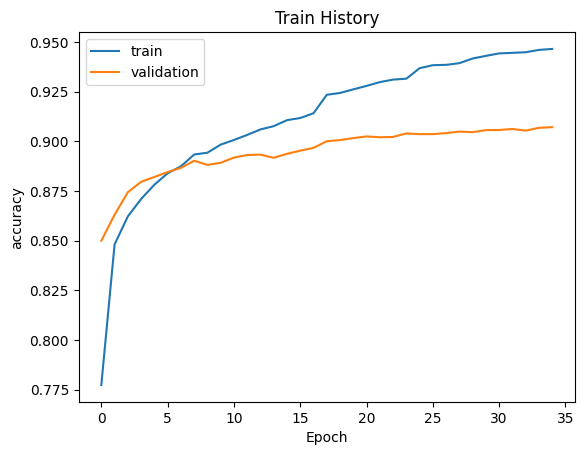

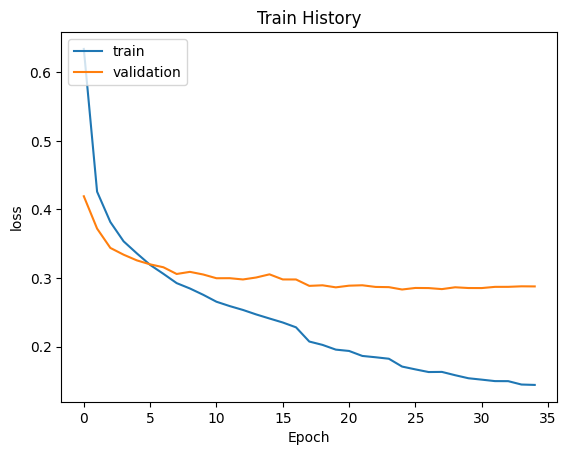

In [64]:
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

show_train_history(train_history,'accuracy','val_accuracy')

show_train_history(train_history,'loss','val_loss')

In [65]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print('測試資料筆數：', len(x_test))
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)')

測試資料筆數： 10000
Test loss: 0.3090
Test accuracy: 0.8980 (89.80%)


全部測試資料預測機率 shape： (10000, 10)
全部測試資料預測標籤 shape： (10000,)


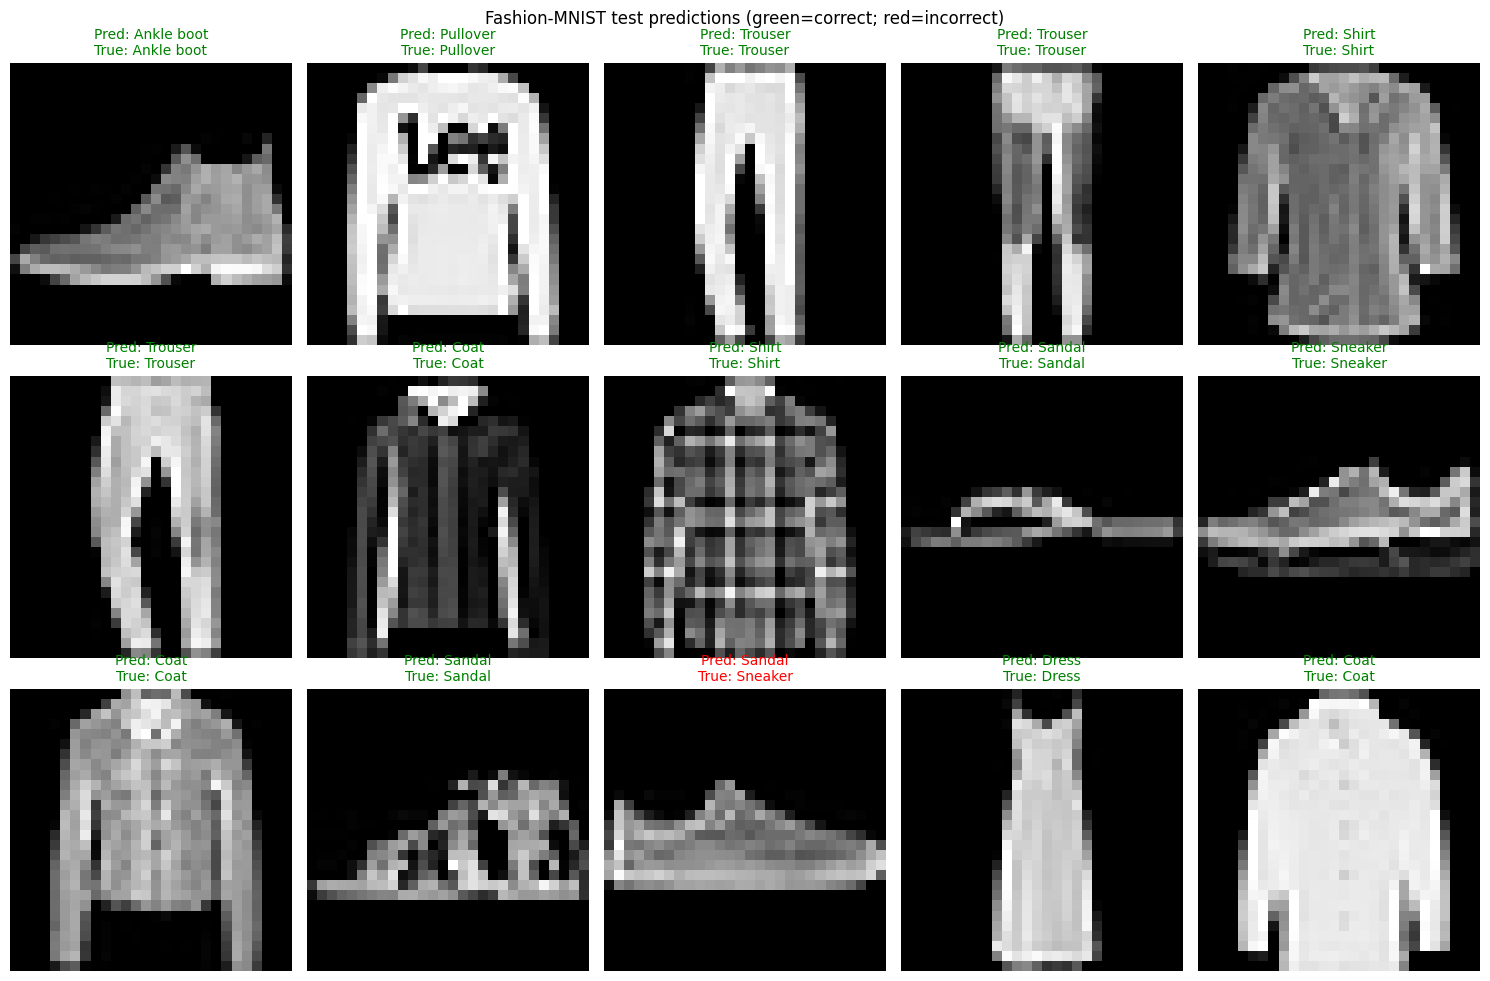

In [66]:
prediction = model.predict(x_test, batch_size=128, verbose=0)
y_predict = np.argmax(prediction, axis=1)
print('全部測試資料預測機率 shape：', prediction.shape)
print('全部測試資料預測標籤 shape：', y_predict.shape)

fig, axes = plt.subplots(3, 5, figsize=(15, 10))
for i, ax in enumerate(axes.flat):
    true_name = class_names[y_test_label[i]]
    pred_name = class_names[y_predict[i]]
    ax.imshow(x_test_image[i], cmap='gray')
    ax.set_title(f'Pred: {pred_name}\nTrue: {true_name}',
                 color='green' if y_predict[i] == y_test_label[i] else 'red', fontsize=10)
    ax.axis('off')
plt.suptitle('Fashion-MNIST test predictions (green=correct; red=incorrect)')
plt.tight_layout()
plt.show()

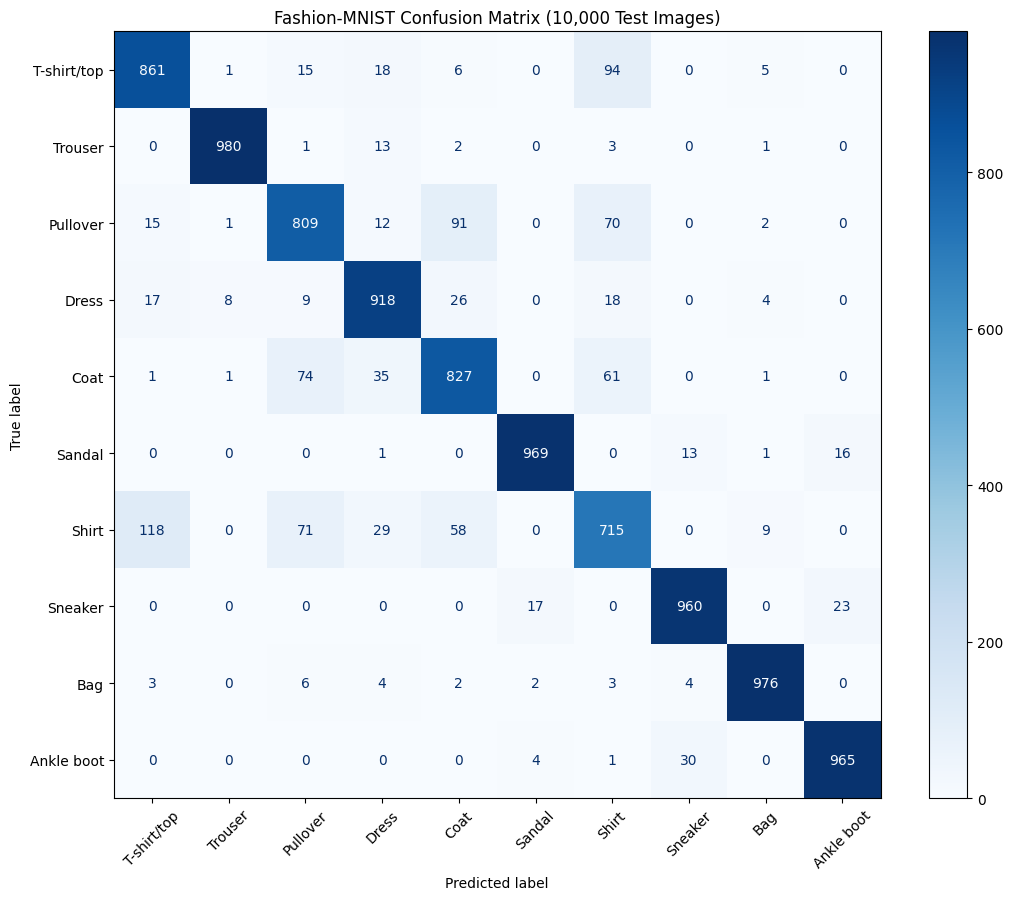

矩陣總筆數： 10000
預測正確筆數： 8980
由混淆矩陣計算的準確率：89.80%


In [67]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_label, y_predict, labels=np.arange(10))
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

fig, ax = plt.subplots(figsize=(11, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, values_format='d', colorbar=True)
ax.set_title('Fashion-MNIST Confusion Matrix (10,000 Test Images)')
plt.tight_layout()
plt.show()

print('矩陣總筆數：', cm.sum())
print('預測正確筆數：', np.trace(cm))
print(f'由混淆矩陣計算的準確率：{np.trace(cm)/cm.sum()*100:.2f}%')

In [68]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [69]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [70]:
model.save('hw3.keras')